In [12]:
from pyspark.sql import SparkSession
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

In [3]:

# Initialize Spark session
spark = (
    SparkSession.builder
    .appName("VicRentalsPipeline")
    .config("spark.sql.shuffle.partitions", "8")  # tune for local dev; raise for larger data
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

# Load parquet file
df = spark.read.parquet("../rea_data/curated/vic_rentals_curated_final.parquet")

# Quick sanity checks
print(f"Rows: {df.count()}, Columns: {len(df.columns)}")
df.printSchema()
df.show(5, truncate=False)

Rows: 12317, Columns: 65
root
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- listing_id: string (nullable = true)
 |-- suburb: string (nullable = true)
 |-- weekly_rent: double (nullable = true)
 |-- date_listed: date (nullable = true)
 |-- bedrooms: double (nullable = true)
 |-- bathrooms: double (nullable = true)
 |-- carspaces: double (nullable = true)
 |-- property_type: string (nullable = true)
 |-- feat_built_in_wardrobes: integer (nullable = true)
 |-- feat_heating: integer (nullable = true)
 |-- feat_dishwasher: integer (nullable = true)
 |-- feat_secure_parking: integer (nullable = true)
 |-- feat_internal_laundry: integer (nullable = true)
 |-- feat_air_conditioning: integer (nullable = true)
 |-- feat_balcony___deck: integer (nullable = true)
 |-- feat_gas: integer (nullable = true)
 |-- feat_floorboards: integer (nullable = true)
 |-- feat_bath: integer (nullable = true)
 |-- feat_intercom: integer (nullable = true)
 |-- feat_ensuite: integer (nu

26/09/25 19:11:40 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+----------+---------+----------+----------------+-----------+-----------+--------+---------+---------+-----------------------+-----------------------+------------+---------------+-------------------+---------------------+---------------------+-------------------+--------+----------------+---------+-------------+------------+-----------------+----------+--------------+----------------------------------+-----------------+-------------------+-------------------------+-----------------------+---------------------+------------------+---------+-------------------+-----------------------+--------+-------------------------------+------------+------------------------------+-----------------+------------------+--------------+-----------------+---------------+---------------------+------------+-------------+-------------+-------------------+------------------------+---------------------+--------------+----------------+-------------------+---------------------------------+---------------+--------

In [20]:
SHP_PATH = "../digital_boundary_files/SA4_2021_AUST_GDA2020.shp"


/home/jovinguyen/miniconda3/envs/tf_env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


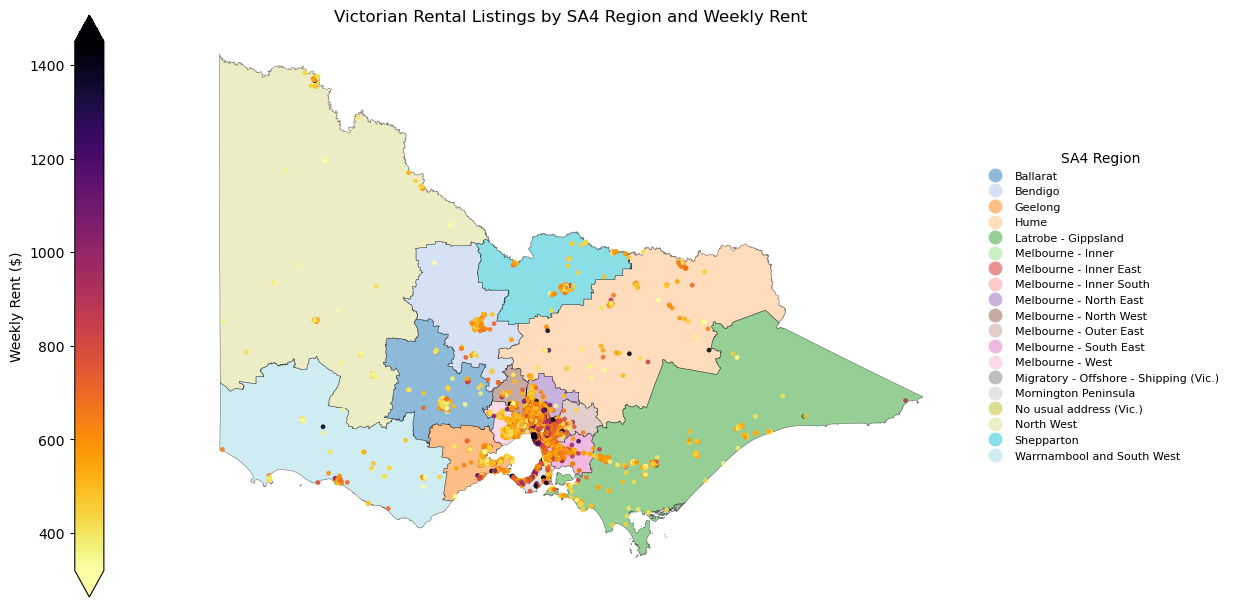

In [23]:
# Convert Spark listings to Pandas
listings_pd = df.select("lat", "lon", "suburb", "weekly_rent").toPandas()

# Build GeoDataFrame from lat/lon points
listings_gdf = gpd.GeoDataFrame(
    listings_pd,
    geometry=gpd.points_from_xy(listings_pd["lon"], listings_pd["lat"]),
    crs="EPSG:4326"
)

# Load SA4 shapefile, filter to Victoria
sa4 = gpd.read_file(SHP_PATH)
sa4_vic = sa4[sa4["STE_NAME21"] == "Victoria"]

# Match CRS
listings_gdf = listings_gdf.to_crs(sa4_vic.crs)

# Outlier-resistant colour scale for rent
vmin, vmax = np.percentile(listings_gdf["weekly_rent"], [2, 98])

fig, ax = plt.subplots(figsize=(13, 10))

# --- Layer 1: SA4 zones, tinted, legend on the right ---
sa4_vic.plot(
    ax=ax,
    column="SA4_NAME21",
    categorical=True,
    cmap="tab20",
    edgecolor="black",
    linewidth=0.4,
    alpha=0.5,              # slightly transparent so points sit clearly on top
    legend=True,
    legend_kwds={
        "loc": "center left",
        "bbox_to_anchor": (1.02, 0.5),
        "fontsize": 8,
        "title": "SA4 Region",
        "frameon": False,
    }
)

# --- Layer 2: listings, coloured by rent, colorbar on the left ---
listings_gdf.plot(
    ax=ax,
    column="weekly_rent",
    cmap="inferno_r",
    markersize=6,
    alpha=0.8,
    vmin=vmin,
    vmax=vmax,
    legend=True,
    legend_kwds={
        "location": "left",
        "shrink": 0.6,
        "label": "Weekly Rent ($)",
        "extend": "both",
        "pad": 0.08,
    }
)

plt.savefig(
    "../Figures/melbourne_sa4_rent_map_full.png",
    dpi=300,                # good print/presentation quality; 150 is fine for on-screen/slides
    bbox_inches="tight",    # includes the legend/colorbar outside the axes, not just the plot area
    facecolor="white"       # avoids a transparent background if you're pasting into a doc/slide
)

ax.set_title("Victorian Rental Listings by SA4 Region and Weekly Rent")
ax.set_axis_off()
plt.tight_layout()
plt.show()

Found 8 zones:
['Melbourne - Inner', 'Melbourne - Inner East', 'Melbourne - Inner South', 'Melbourne - North East', 'Melbourne - North West', 'Melbourne - Outer East', 'Melbourne - South East', 'Melbourne - West']


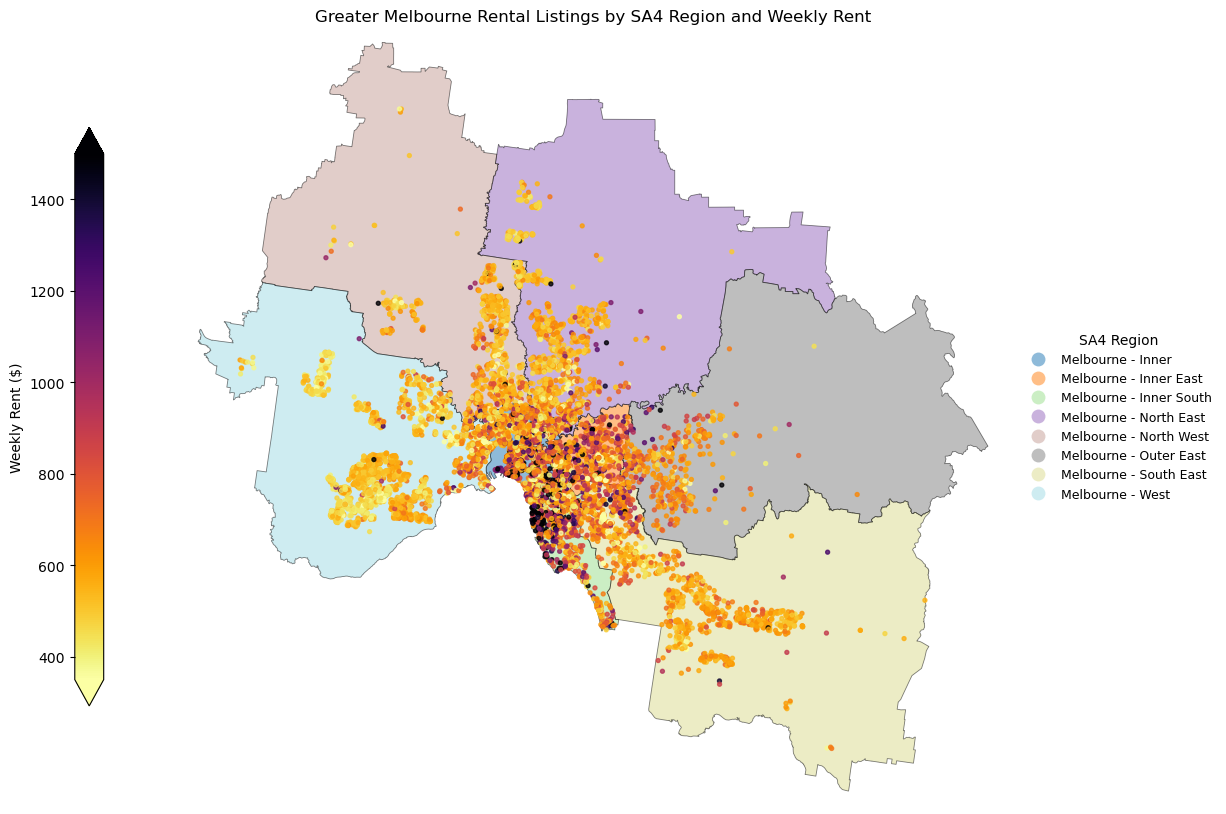

In [24]:
# Filter to SA4 zones with "Melbourne" in the name
sa4_melb = sa4[sa4["SA4_NAME21"].str.contains("Melbourne", case=False, na=False)]

print(f"Found {len(sa4_melb)} zones:")
print(sa4_melb["SA4_NAME21"].tolist())

# Match CRS
listings_gdf = listings_gdf.to_crs(sa4_melb.crs)

# Clip listings to just those inside the Melbourne SA4 zones
listings_melb = gpd.sjoin(listings_gdf, sa4_melb[["SA4_NAME21", "geometry"]], how="inner", predicate="within")

# Outlier-resistant colour scale for rent (computed on the Melbourne subset only)
vmin, vmax = np.percentile(listings_melb["weekly_rent"], [2, 98])

fig, ax = plt.subplots(figsize=(13, 10))

# --- Layer 1: SA4 zones, tinted, legend on the right ---
sa4_melb.plot(
    ax=ax,
    column="SA4_NAME21",
    categorical=True,
    cmap="tab20",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.5,
    legend=True,
    legend_kwds={
        "loc": "center left",
        "bbox_to_anchor": (1.02, 0.5),
        "fontsize": 9,
        "title": "SA4 Region",
        "frameon": False,
    }
)

# --- Layer 2: listings, coloured by rent, colorbar on the left ---
listings_melb.plot(
    ax=ax,
    column="weekly_rent",
    cmap="inferno_r",
    markersize=8,
    alpha=0.8,
    vmin=vmin,
    vmax=vmax,
    legend=True,
    legend_kwds={
        "location": "left",
        "shrink": 0.6,
        "label": "Weekly Rent ($)",
        "extend": "both",
        "pad": 0.08,
    }
)

plt.savefig(
    "../Figures/melbourne_sa4_rent_map.png",
    dpi=300,                # good print/presentation quality; 150 is fine for on-screen/slides
    bbox_inches="tight",    # includes the legend/colorbar outside the axes, not just the plot area
    facecolor="white"       # avoids a transparent background if you're pasting into a doc/slide
)


# Zoom the plot to the Melbourne zones' extent (with a small buffer)
minx, miny, maxx, maxy = sa4_melb.total_bounds
buffer = 0.02
ax.set_xlim(minx - buffer, maxx + buffer)
ax.set_ylim(miny - buffer, maxy + buffer)

ax.set_title("Greater Melbourne Rental Listings by SA4 Region and Weekly Rent")
ax.set_axis_off()
plt.tight_layout()
plt.show()